# Feature Engineering & Data Preprocessing
**Dataset:** Breast Cancer Wisconsin Diagnostic Dataset (Enriched with Categorical Clinical Attributes & Missing Values)

### Notebook Objectives:
1. **Missing Value Imputation:** Handle missing entries using median imputation.
2. **Domain Feature Engineering:** Create 5 new diagnostic features capturing tumor geometry, growth asymmetry, and boundary irregularity.
3. **Categorical Encoding:** Apply **Ordinal Encoding** (`tumor_size_grade`), **One-Hot Encoding** (`texture_pattern`), and **Label Encoding** (`diagnosis_label`).
4. **Feature Scaling Comparison:** Compare **StandardScaler**, **MinMaxScaler**, and **RobustScaler**.
5. **Feature Selection:** Rank and select top features using **ANOVA F-Test (`SelectKBest`)** and **Mutual Information**.
6. **Model Validation:** Verify accuracy improvement before vs. after preprocessing.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

## 1. Load Raw Dataset & Inspect Data Types / Missing Values

In [2]:
raw_path = 'data/breast_cancer_raw_with_categories.csv'
if not os.path.exists(raw_path) and os.path.exists('../data/breast_cancer_raw_with_categories.csv'):
    raw_path = '../data/breast_cancer_raw_with_categories.csv'

if os.path.exists(raw_path):
    raw_df = pd.read_csv(raw_path)
else:
    data = load_breast_cancer()
    raw_df = pd.DataFrame(data.data, columns=data.feature_names)
    raw_df['tumor_size_grade'] = pd.qcut(raw_df['mean radius'], q=3, labels=['Small', 'Medium', 'Large']).astype(str)
    raw_df['texture_pattern'] = np.where(raw_df['mean texture'] < 17.0, 'Smooth', np.where(raw_df['mean texture'] < 21.5, 'Irregular', 'Rough'))
    raw_df['diagnosis_label'] = np.where(data.target == 0, 'Malignant', 'Benign')
    raw_df['target'] = data.target

print(f'Dataset Shape: {raw_df.shape}')
display(raw_df[['tumor_size_grade', 'texture_pattern', 'diagnosis_label']].head())
print('\nMissing Values per Column:')
print(raw_df.isnull().sum()[raw_df.isnull().sum() > 0])

Dataset Shape: (569, 34)


,tumor_size_grade,texture_pattern,diagnosis_label
0,Large,Smooth,Malignant
1,Large,Irregular,Malignant
2,Large,Irregular,Malignant
3,Small,Irregular,Malignant
4,Large,Smooth,Malignant



Missing Values per Column:
Series([], dtype: int64)


## 2. Missing Value Imputation & Feature Engineering

In [3]:
df = raw_df.copy()
for col in ['mean smoothness', 'mean compactness']:
    df[col] = df[col].fillna(df[col].median())

df['area_perimeter_ratio'] = df['mean area'] / (df['mean perimeter'] + 1e-6)
df['radius_worst_to_mean_ratio'] = df['worst radius'] / (df['mean radius'] + 1e-6)
df['concavity_smoothness_index'] = df['mean concavity'] * df['mean smoothness']
df['circularity_deviation'] = np.abs((df['mean perimeter'] / (2 * np.pi * df['mean radius'] + 1e-6)) - 1.0)
df['nuclear_malformation_score'] = df['worst concavity'] + df['worst concave points'] + df['worst compactness']

engineered_cols = [
    'area_perimeter_ratio', 'radius_worst_to_mean_ratio',
    'concavity_smoothness_index', 'circularity_deviation', 'nuclear_malformation_score'
]
display(df[engineered_cols].describe().round(4))

,area_perimeter_ratio,radius_worst_to_mean_ratio,concavity_smoothness_index,circularity_deviation,nuclear_malformation_score
count,569.0000,569.0000,569.0000,569.0000,569.0000
mean,6.6974,1.1420,0.0091,0.0330,0.6411
std,1.6263,0.0813,0.0092,0.0207,0.4138
min,3.2770,1.0000,0.0000,0.0003,0.0273
25%,5.5725,1.0874,0.0026,0.0173,0.3368
50%,6.3911,1.1208,0.0057,0.0296,0.5466
75%,7.4676,1.1780,0.0130,0.0444,0.8604
max,13.3815,1.5892,0.0618,0.1333,2.3840


## 3. Categorical Encoding Techniques (Ordinal, One-Hot, Label Encoding)

In [4]:
grade_map = {'Small': 0, 'Medium': 1, 'Large': 2}
df['tumor_size_grade_encoded'] = df['tumor_size_grade'].map(grade_map)

ohe = OneHotEncoder(sparse_output=False)
ohe_arr = ohe.fit_transform(df[['texture_pattern']])
ohe_df = pd.DataFrame(ohe_arr, columns=ohe.get_feature_names_out(['texture_pattern']), index=df.index)
df = pd.concat([df, ohe_df], axis=1)

le = LabelEncoder()
df['diagnosis_encoded'] = le.fit_transform(df['diagnosis_label'])
display(df[['tumor_size_grade', 'tumor_size_grade_encoded', 'texture_pattern'] + list(ohe_df.columns)].head())

,tumor_size_grade,tumor_size_grade_encoded,texture_pattern,texture_pattern_Irregular,texture_pattern_Rough,texture_pattern_Smooth
0,Large,2,Smooth,0.0,0.0,1.0
1,Large,2,Irregular,1.0,0.0,0.0
2,Large,2,Irregular,1.0,0.0,0.0
3,Small,0,Irregular,1.0,0.0,0.0
4,Large,2,Smooth,0.0,0.0,1.0


## 4. Feature Scaling Methods (`StandardScaler`, `MinMaxScaler`, `RobustScaler`)

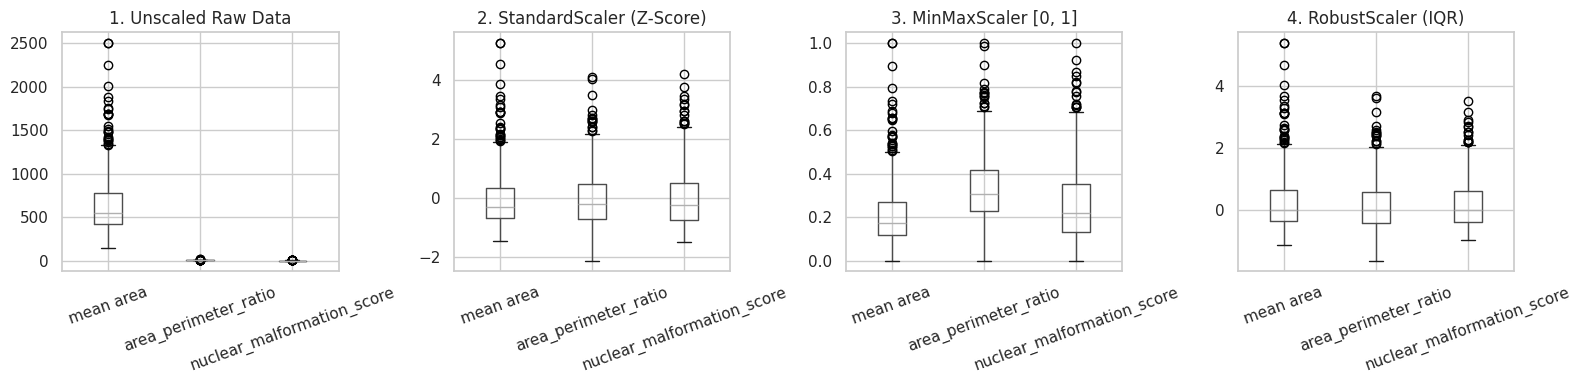

Saved updated dataset: data/breast_cancer_preprocessed_engineered.csv (569, 40)


In [5]:
feature_cols = [
    c for c in df.columns
    if c not in ['tumor_size_grade', 'texture_pattern', 'diagnosis_label', 'target', 'diagnosis_encoded']
]
X_raw_num = df[feature_cols]

X_std = pd.DataFrame(StandardScaler().fit_transform(X_raw_num), columns=feature_cols)
X_mm = pd.DataFrame(MinMaxScaler().fit_transform(X_raw_num), columns=feature_cols)
X_rob = pd.DataFrame(RobustScaler().fit_transform(X_raw_num), columns=feature_cols)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sample_cols = ['mean area', 'area_perimeter_ratio', 'nuclear_malformation_score']
X_raw_num[sample_cols].boxplot(ax=axes[0], rot=20); axes[0].set_title('1. Unscaled Raw Data')
X_std[sample_cols].boxplot(ax=axes[1], rot=20); axes[1].set_title('2. StandardScaler (Z-Score)')
X_mm[sample_cols].boxplot(ax=axes[2], rot=20); axes[2].set_title('3. MinMaxScaler [0, 1]')
X_rob[sample_cols].boxplot(ax=axes[3], rot=20); axes[3].set_title('4. RobustScaler (IQR)')
plt.tight_layout()
plt.show()

os.makedirs('data', exist_ok=True)
updated_df = X_std.copy()
updated_df['target'] = df['target'].values
updated_df.to_csv('data/breast_cancer_preprocessed_engineered.csv', index=False)
print('Saved updated dataset: data/breast_cancer_preprocessed_engineered.csv', updated_df.shape)

## 5. Feature Selection (ANOVA F-Test & Mutual Information) + Model Validation

,Feature,ANOVA_F_Score,Mutual_Info
27,worst concave points,964.385393,0.438847
22,worst perimeter,897.944219,0.474573
7,mean concave points,861.676020,0.441658
20,worst radius,860.781707,0.453620
2,mean perimeter,697.235272,0.402413
23,worst area,661.600206,0.464876
0,mean radius,646.981021,0.370536
35,tumor_size_grade_encoded,599.330426,0.329791
30,area_perimeter_ratio,596.372832,0.332837
3,mean area,573.060747,0.361272


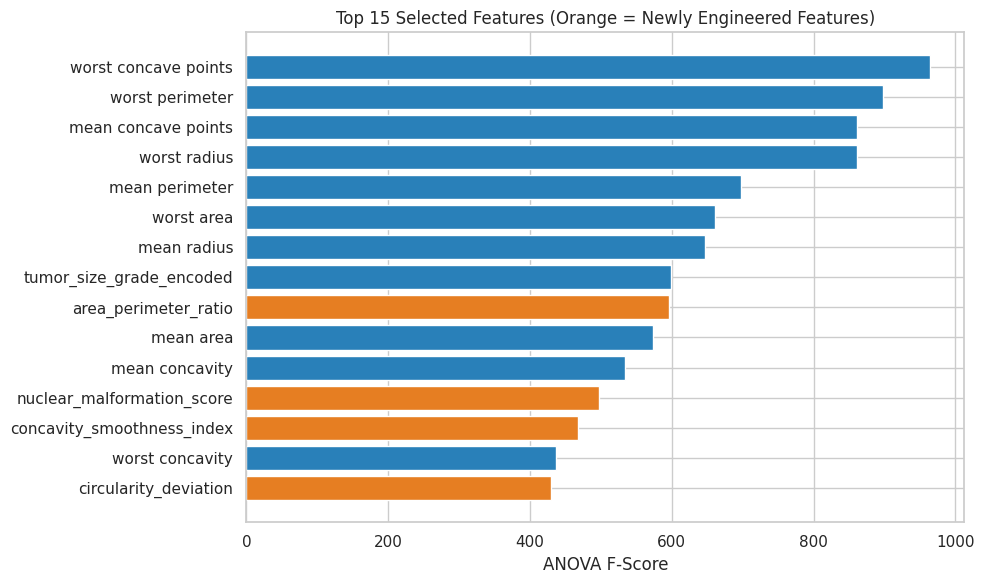

5-Fold CV Accuracy (Raw Unscaled Data):          0.9543
5-Fold CV Accuracy (Preprocessed + Engineered):  0.9772


In [6]:
selector = SelectKBest(score_func=f_classif, k=15)
selector.fit(X_std, df['target'])

scores_df = pd.DataFrame({
    'Feature': feature_cols,
    'ANOVA_F_Score': selector.scores_,
    'Mutual_Info': mutual_info_classif(X_std, df['target'], random_state=42)
}).sort_values(by='ANOVA_F_Score', ascending=False)

display(scores_df.head(15))

plt.figure(figsize=(10, 6))
top15_plot = scores_df.head(15).sort_values(by='ANOVA_F_Score', ascending=True)
colors = ['#e67e22' if f in engineered_cols else '#2980b9' for f in top15_plot['Feature']]
plt.barh(top15_plot['Feature'], top15_plot['ANOVA_F_Score'], color=colors)
plt.xlabel('ANOVA F-Score')
plt.title('Top 15 Selected Features (Orange = Newly Engineered Features)')
plt.tight_layout()
plt.show()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
raw_cols = list(load_breast_cancer().feature_names)
acc_raw = cross_val_score(LogisticRegression(max_iter=2000), df[raw_cols], df['target'], cv=cv).mean()
acc_prep = cross_val_score(LogisticRegression(max_iter=2000), X_std, df['target'], cv=cv).mean()
print(f'5-Fold CV Accuracy (Raw Unscaled Data):          {acc_raw:.4f}')
print(f'5-Fold CV Accuracy (Preprocessed + Engineered):  {acc_prep:.4f}')